In [49]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd 
import seaborn as sns

In [50]:
DATA_PATH ='data/train-house-prices-advanced-regression-techniques.csv'
house_df = pd.read_csv(DATA_PATH)
house_df.head()

,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [51]:

house_df.describe().transpose()

,count,mean,std,min,25%,50%,75%,max
Id,1460.0,730.500000,421.610009,1.0,365.75,730.5,1095.25,1460.0
MSSubClass,1460.0,56.897260,42.300571,20.0,20.00,50.0,70.00,190.0
LotFrontage,1201.0,70.049958,24.284752,21.0,59.00,69.0,80.00,313.0
LotArea,1460.0,10516.828082,9981.264932,1300.0,7553.50,9478.5,11601.50,215245.0
OverallQual,1460.0,6.099315,1.382997,1.0,5.00,6.0,7.00,10.0
OverallCond,1460.0,5.575342,1.112799,1.0,5.00,5.0,6.00,9.0
YearBuilt,1460.0,1971.267808,30.202904,1872.0,1954.00,1973.0,2000.00,2010.0
YearRemodAdd,1460.0,1984.865753,20.645407,1950.0,1967.00,1994.0,2004.00,2010.0
MasVnrArea,1452.0,103.685262,181.066207,0.0,0.00,0.0,166.00,1600.0
BsmtFinSF1,1460.0,443.639726,456.098091,0.0,0.00,383.5,712.25,5644.0


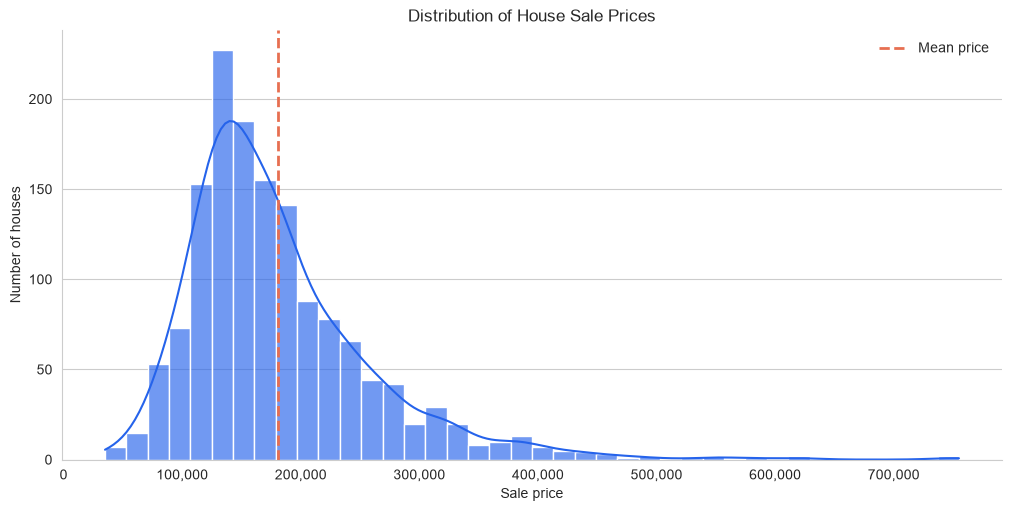

In [52]:
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(10, 5), layout="constrained")
    sns.histplot(house_df, x="SalePrice", bins=40, kde=True, color="#2563EB", alpha=0.65, ax=ax)
    ax.axvline(house_df["SalePrice"].mean(), color="#E76F51", ls="--", lw=2, label="Mean price")
    ax.set(title="Distribution of House Sale Prices", xlabel="Sale price", ylabel="Number of houses")
    ax.xaxis.set_major_formatter("{x:,.0f}")
    ax.grid(axis="x", visible=False)
    ax.legend(frameon=False)
    sns.despine(ax=ax)
    plt.show()

Sale Prices has a Right-skewed distribution  
Most house prices is in 100K to 200K, a small numbers are priced above 400K,creating long right tail  
Therefore:  
The mean may be pulled upward by the high-priced, that means it less represents for typical house prices  
The house prices are asymmetrically distributed, with most houses concentrated in the lower price range.  

In [53]:
house_df.isnull().sum()

Id                 0
MSSubClass         0
MSZoning           0
LotFrontage      259
LotArea            0
                ... 
MoSold             0
YrSold             0
SaleType           0
SaleCondition      0
SalePrice          0
Length: 81, dtype: int64

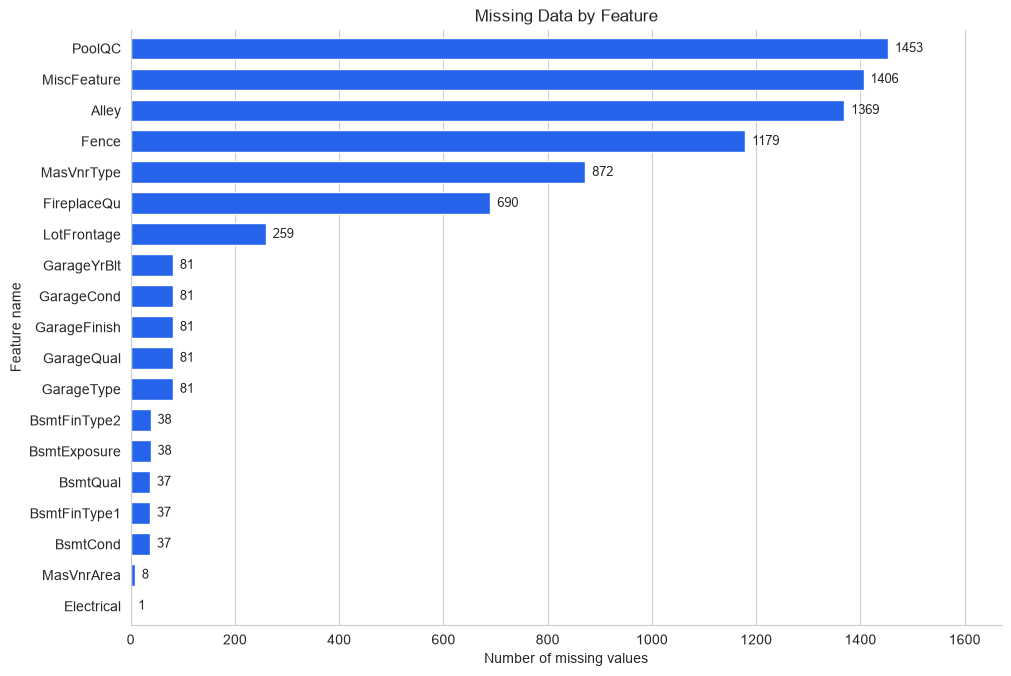

In [54]:
missing = house_df.isna().sum().loc[lambda counts: counts.gt(0)].sort_values()
with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(10, max(4, len(missing) * 0.35)), layout="constrained")
    missing.plot.barh(ax=ax, color="#2563EB", width=0.7)
    ax.bar_label(ax.containers[0], padding=5, fontsize=9)
    ax.set(title="Missing Data by Feature", xlabel="Number of missing values", ylabel="Feature name")
    ax.set_xlim(0, missing.max() * 1.15)
    ax.grid(axis="y", visible=False)
    ax.set_axisbelow(True)
    sns.despine(ax=ax)
    plt.show()

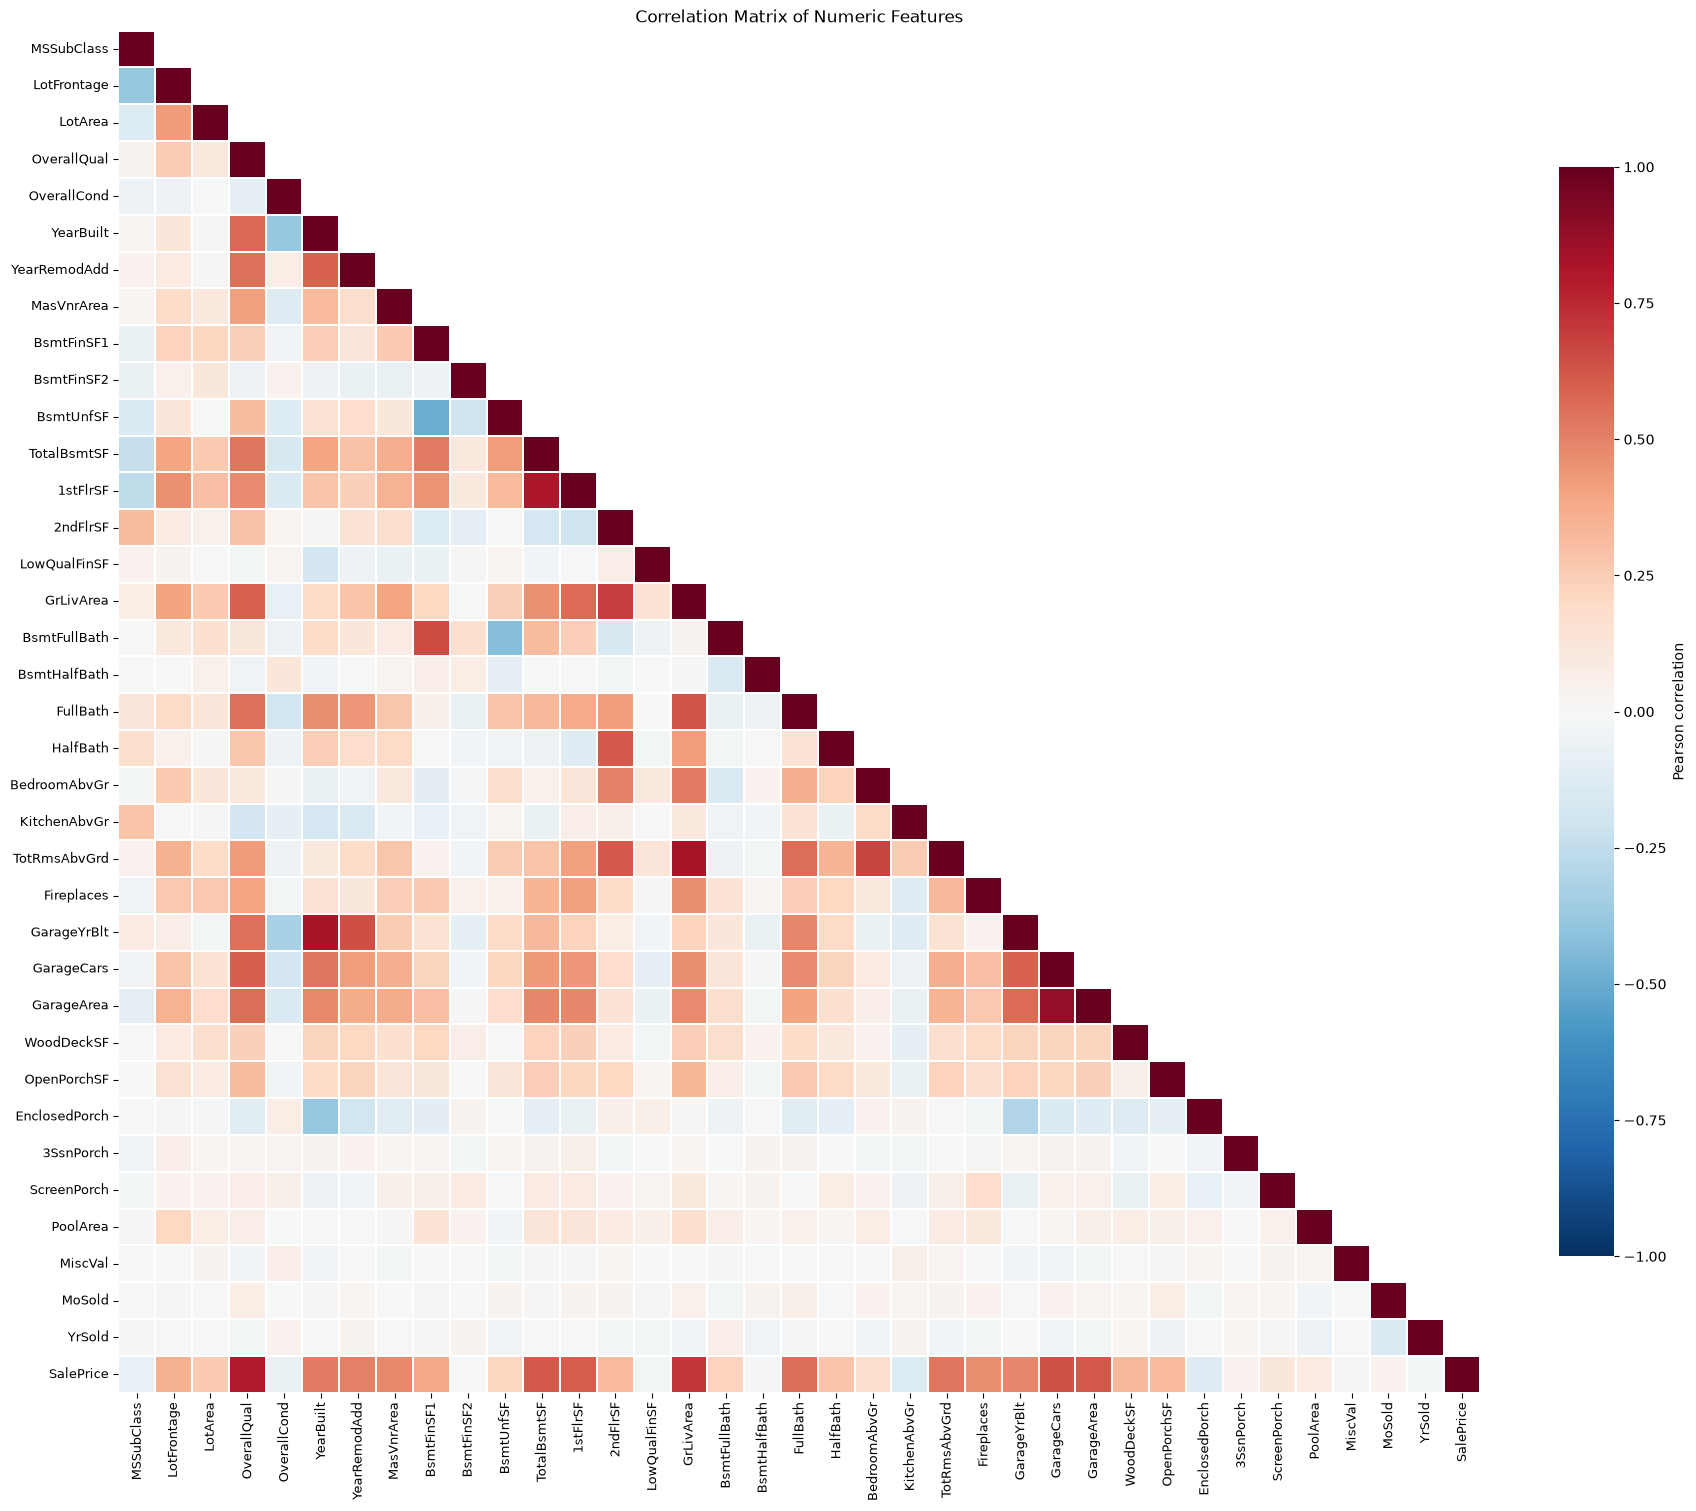

In [55]:
correlation = house_df.select_dtypes(include="number").drop(columns="Id").corr()
fig, ax = plt.subplots(figsize=(18, 15), layout="constrained")
sns.heatmap(correlation, mask=np.triu(np.ones_like(correlation, dtype=bool), k=1),
            cmap="RdBu_r", center=0, vmin=-1, vmax=1, square=True, linewidths=0.3,
            cbar_kws={"label": "Pearson correlation", "shrink": 0.8}, ax=ax)
ax.set(title="Correlation Matrix of Numeric Features", xlabel="", ylabel="")
ax.tick_params(axis="both", labelsize=9)
plt.show()

Getting Top 10 Highest correlation numeric Feature  with target

In [58]:
correlated_features = correlation['SalePrice'].sort_values(ascending = False).head(11)
correlated_features

SalePrice       1.000000
OverallQual     0.790982
GrLivArea       0.708624
GarageCars      0.640409
GarageArea      0.623431
TotalBsmtSF     0.613581
1stFlrSF        0.605852
FullBath        0.560664
TotRmsAbvGrd    0.533723
YearBuilt       0.522897
YearRemodAdd    0.507101
Name: SalePrice, dtype: float64

Getting Top 10 Highest correlation numeric Feature  with together

In [59]:
feature_corr = correlation.drop(index="SalePrice", columns="SalePrice")
pairs = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool)).stack()
pairs[pairs.abs() >= 0.5].sort_values(key=abs, ascending=False).head(10)

GarageCars    GarageArea      0.882475
YearBuilt     GarageYrBlt     0.825667
GrLivArea     TotRmsAbvGrd    0.825489
TotalBsmtSF   1stFlrSF        0.819530
2ndFlrSF      GrLivArea       0.687501
BedroomAbvGr  TotRmsAbvGrd    0.676620
BsmtFinSF1    BsmtFullBath    0.649212
YearRemodAdd  GarageYrBlt     0.642277
GrLivArea     FullBath        0.630012
2ndFlrSF      TotRmsAbvGrd    0.616423
dtype: float64

Explore distribution of TOP 10 numeric

In [75]:
feature_chosen = correlation['SalePrice'].sort_values(ascending = False).head(11).index[1:]
feature_chosen

Index(['OverallQual', 'GrLivArea', 'GarageCars', 'GarageArea', 'TotalBsmtSF',
       '1stFlrSF', 'FullBath', 'TotRmsAbvGrd', 'YearBuilt', 'YearRemodAdd'],
      dtype='str')

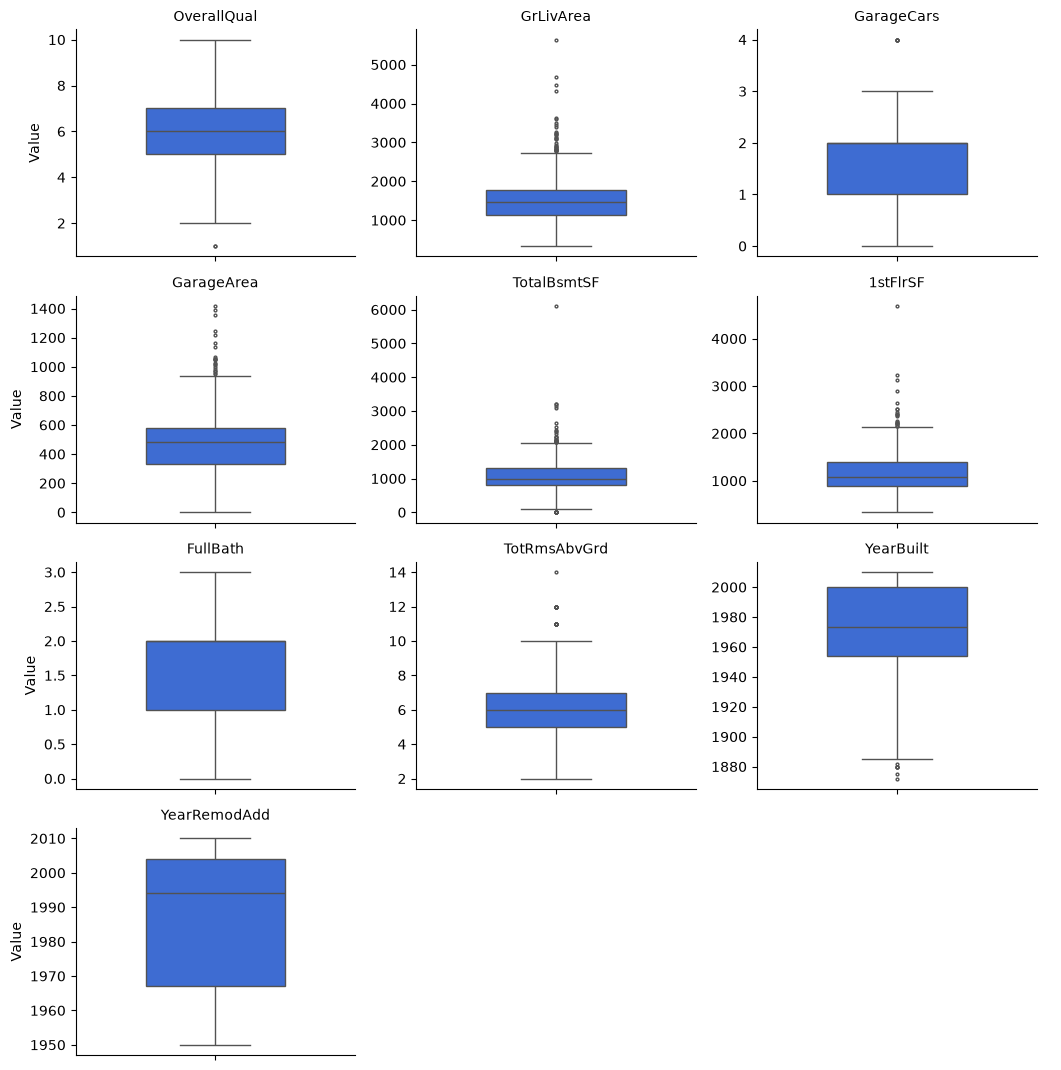

In [76]:
g = sns.catplot(data=house_df[feature_chosen].melt(var_name="Feature", value_name="Value"),
                col="Feature", y="Value", kind="box", col_wrap=3, sharey=False,
                height=2.7, aspect=1.3, color="#2563EB", width=0.5, fliersize=2)
g.set_titles("{col_name}").set_axis_labels("", "Value")
plt.show()

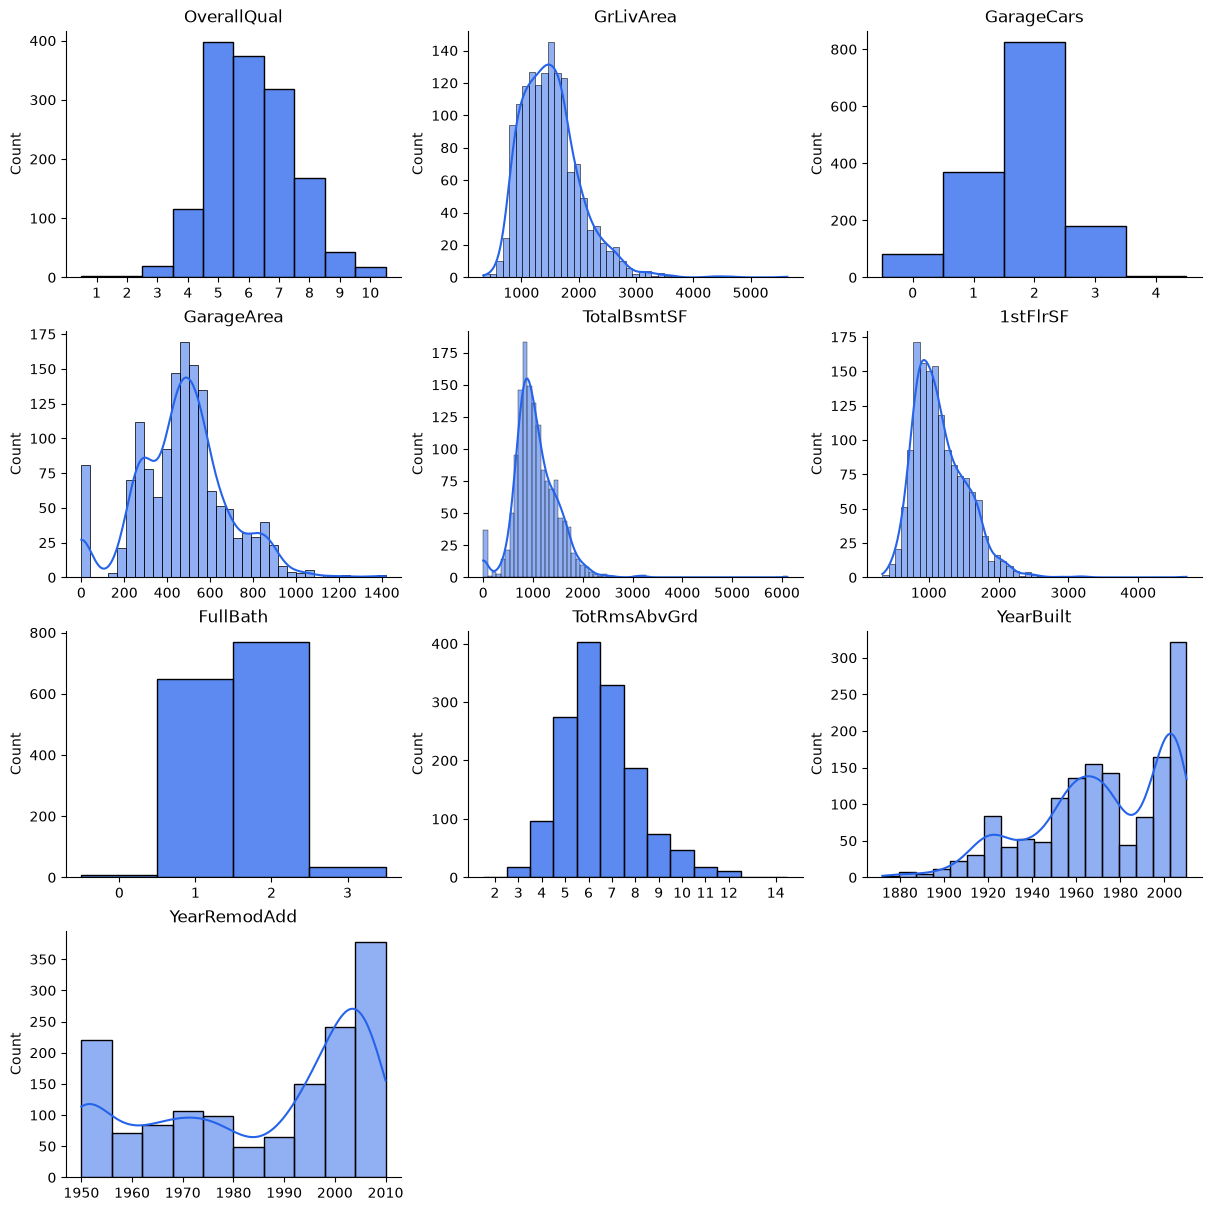

In [77]:
rows = (len(feature_chosen) + 2) // 3
fig, axes = plt.subplots(rows, 3, figsize=(12, rows * 3), layout="constrained", squeeze=False)
for ax, feature in zip(axes.flat, feature_chosen):
    values = house_df[feature].dropna()
    discrete = values.nunique() <= 20 and values.mod(1).eq(0).all()
    sns.histplot(values, bins="fd", discrete=discrete, kde=not discrete, color="#2563EB", ax=ax)
    ax.set(title=feature, xlabel="", ylabel="Count")
    if discrete:
        ax.set_xticks(sorted(values.unique()))
for ax in axes.flat[len(feature_chosen):]:
    ax.set_visible(False)
sns.despine(fig=fig)
plt.show()